Analysis the firing patterns of pyramidal cells and inhibitory interneurons to:
1) Identify types of interneurons recorded
2) Examine how these patterns change during development

### 1) Identify interneuron types

**Axo-axonic** (Natalie Schieferstein thesis)
- selectively active before SWR (increase f.r. at beginning of a SWR event).
- *during theta*: fire out-of-phase with pyramidal cells. AA exhibit the highest firing probability around the peak of the pyr layer extracellular theta, i.e. when the average pyr cell is most hyperpolarized (Klausberger, 2005).
- *during ripples*: become silent after highest amplitude of ripple episode (Klausberger et al 2005)

**OLM**
- selectively silenced during ripples
- *during theta*: fire in phase with pyramidal cells (just before)
  
**PV+ BC** (Natalie Schieferstein thesis)
- Selectively active during SWR.
- *during theta*: at descending phase of oscillations recorded extracellularly.- *during ripples*: Highest discharge probability around the peak of LFP ripple power (Klausberger et al 2003, while pyr cells are phase-locked around the through (Buzasaki et al 1992, Klausberger et al 2003). 
Fire phase-locked, and 1-2ms after the pyramidal cells during the ascending phase of each LFP ripple cycle (~60-90deg.; Csicsvari et al 1999; Klausberger et al 2003; Sullivan et al 20..)1

**Bistratified**
- selectively active during ripple
- *during theta* :: in phase with pyr
- *during ripples*: no phase preference; fire with high frequency throughout all ripple episodes (Klausberger et al 2005) 


#### 1.1) Identify interneurons selectively silenced (OLM + AA) and activated (BC + Bistr.) during ripples 

In [1]:
import os
import re
import h5py
import numpy as np
import helper_functions.rhythm_detection as rd
import helper_functions.signal_processing as sp
from sklearn.preprocessing import MinMaxScaler
from collections import defaultdict
import matplotlib.pyplot as plt

In [2]:
# To determine if a neuron is spiking outside or inside a SWR event, we use the 'short ripple' data set, 
# since AA cells can also be spiking in the beginning of a ripple

pathway_win = r"D:\data_CA1\hdf5_NoHighGain_new"     # directory where data files are stored
trial_files = [f for f in os.listdir(pathway_win)]  # Load name of all rat files

Spiking patterns during ripples

In [ ]:
# SAME-SIZED AGE GROUPS

# Define color palette
palette = ['#6673AF', '#ECB851', '#708238', '#B51700']
age_labels = ['P17-21', "P22-26", "P27-32", "Adult"]

def age_group(age):
    if age <= 21:
        return age_labels[0]    
    elif age <= 26:
        return age_labels[1]
    elif age <= 32:
        return age_labels[2]
    else:
        return age_labels[3]

In [ ]:
# Laurenz's 2019 PAPER AGE GROUPS
# Define color palette
palette = ['#6673AF', '#ECB851', '#708238', '#B51700']
age_labels = ['P17-20', "P21-24", "P25-32", "Adult"]

def age_group(age):
    if age <= 20:
        return age_labels[0]    
    elif age <= 24:
        return age_labels[1]
    elif age <= 32:
        return age_labels[2]
    else:
        return age_labels[3]

In [ ]:
# CIRCUITRY CHANGES BASED AGE GROUPS
# Define color palette
palette = ['#6673AF', '#708238', '#B51700']
age_labels = ['P17-23', "P23-32", "Adult"]

def age_group(age):
    if age <= 23:
        return age_labels[0]    
    elif age <= 32:
        return age_labels[1]
    else:
        return age_labels[2]

In [5]:
# NON_ADULTS AND ADULTS AGE GROUP
# Define color palette
palette = ['#6673AF', '#B51700']
age_labels = ['P17-32', "Adult"]

def age_group(age):   
    if age <= 32:
        return age_labels[0]
    else:
        return age_labels[1]

In [6]:
bin_fr = 0.005 # sec
eeg_sr = 4800
inhib_neurons = defaultdict(lambda:defaultdict(list))

for trial in trial_files:
    file_path = os.path.join(pathway_win,trial)

    with h5py.File(file_path,'r') as f:
        spk_times_sleep = f['spike_times']['postRun_sleep'][:]
        cell_type = f['cell_type'][:]
        ripp_events =  f['ripp_times']['postRun_sleep'][:]
        ripp_modulation = f['ripp_modulation'][:]
        ripp_modulation_sign = f['ripp_modulation_sign'][:]
        SWR_lfp_ch = f['SWR_lfp_ch'][()]
        lfp_sleep =  f['lfp']['postRun_sleep'][SWR_lfp_ch]

    duration_sleep = len(lfp_sleep)/eeg_sr
 
    mask_inhib = (cell_type==b'inhib') 
    inhib_spks = spk_times_sleep[mask_inhib]
    mod = ripp_modulation[mask_inhib]         # ripp modulation computed in python code. to confirm all is coherent
    mod_sign = ripp_modulation_sign[mask_inhib] # ripp modulation sign (is it statistically significant? then 1)
    total_inhib_neurons = len(inhib_spks)

    match = re.search(r"P(\d+)", trial)
    age = int(match.group(1))
    age_entry = age_group(age)

    for i in range(total_inhib_neurons):
        # Compute firing rate from spk times
        full_firing_rate, time_bins = sp.compute_fr(inhib_spks[i], 
                                                t_range=[0, duration_sleep], 
                                                bin_size=bin_fr)
        # Ripple modulation
        # Compute ripple modulation as difference between ripple and non-ripple mean activity
        bins_notRipp, bins_ripp = 10, 10
        zscored_fr_ripp,_ = rd.ripp_modulation(full_firing_rate, ripp_events, bins_notRipp=bins_notRipp, bins_ripp=bins_ripp) # compute zscore_fr around ripple for plotting

        # Optional: Example of normalized fr for an interneuron, before, during and after ripples
  #      if trial == trial_files[12] or trial == trial_files[13] or trial == trial_files[14]:
  #          print('good trial')
  #          fig, ax_fr = plt.subplots()
  #          ax_fr.plot(zscored_fr_ripp, color='b')
  #          ax_fr.axvline(x=bins_notRipp, linestyle='--', color='gray', label='Ripple Start')
  #          ax_fr.axvline(x=(bins_notRipp+bins_ripp), linestyle='--', color='gray', label='Ripple End')
  #          ax_fr.set_ylabel('Firing Rate (Hz)')
  #          ax_fr.set_xlabel('Time (normalized)')
  #          ax_fr.set_title(f'Neuron {i}, Ripple modulation here: {mod[i]}, sign: {mod_sign[i]}')

        inhib_neurons[age_entry]['fr'].append(zscored_fr_ripp)
        inhib_neurons[age_entry]['ripp_mod'].append(mod[i])
        inhib_neurons[age_entry]['ripp_mod_sign'].append(mod_sign[i])

C:\Users\Florencia\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Florencia\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


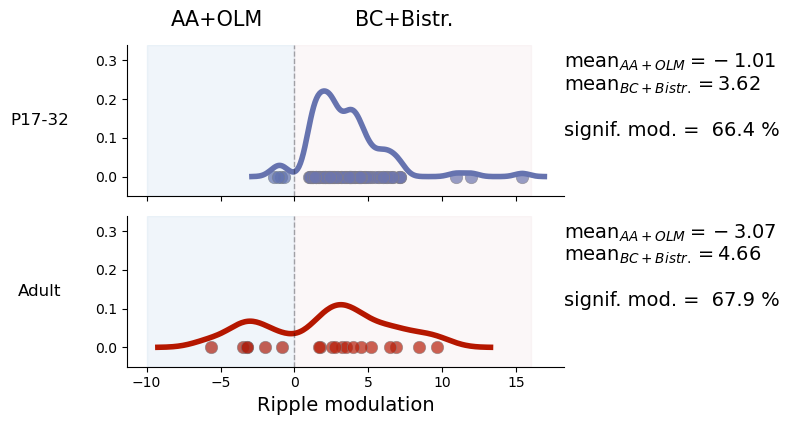

In [8]:
from matplotlib.gridspec import GridSpec
from matplotlib.colors import to_rgba
import seaborn as sns

fig, axes = plt.subplots(nrows=len(age_labels), ncols=1, figsize=(8, 8), sharex=True)

for i, (ax, group) in enumerate(zip(axes, age_labels)):
    ripp_mod = np.array(inhib_neurons[group]['ripp_mod'])
    ripp_mod_sign = np.array(inhib_neurons[group]['ripp_mod_sign'])

    total_neurons = len(ripp_mod_sign)
    signif_modulated = np.count_nonzero(ripp_mod_sign)
    frac_signif_modulated = signif_modulated/total_neurons

    mask = (np.abs(ripp_mod) < 1000) & (ripp_mod_sign ==1)
    valid_ripp = ripp_mod[mask]

    pos_mask = valid_ripp>0
    neg_mask = valid_ripp<0

    pos_mean = np.mean(valid_ripp[pos_mask])
    neg_mean = np.mean(valid_ripp[neg_mask])

    # KDE plot
    sns.kdeplot(valid_ripp, ax=ax, bw_adjust=0.5, color=palette[i], linewidth=4)

    # Scatter plot at y=0
    ax.scatter(valid_ripp, np.zeros(len(valid_ripp)),
               c=palette[i], s=80, alpha=0.7,
               edgecolors='grey', linewidths=0.5)

    ax.text(1.0, 0.85, rf"$\mathrm{{mean}}_{{AA+OLM}} = {neg_mean:.2f}$", transform=ax.transAxes,fontsize=14)
    ax.text(1.0, 0.7, rf"$\mathrm{{mean}}_{{BC+Bistr.}} = {pos_mean:.2f}$", transform=ax.transAxes,fontsize=14)
    ax.text(1.0, 0.4, f"signif. mod. = {frac_signif_modulated*100 : .1f} %", transform=ax.transAxes,fontsize=14)
    ax.set_ylabel(group, fontsize=12, rotation=0, labelpad=40, va='center')
    ax.set_ylim(-0.05,0.34)
    #ax.set_yticks([])
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.axvline(0, color='k', linewidth=1, linestyle='--', alpha=0.3)
    ax.axvspan(-10, 0, alpha=0.07, color='#317EC2')
    ax.axvspan(0, 16, alpha=0.07, color='#D092A1')

fig.text(0.22, 1.01, "AA+OLM", fontsize=15)
fig.text(0.45, 1.01, "BC+Bistr.", fontsize=15)

axes[-1].set_xlabel('Ripple modulation', fontsize=14)
plt.savefig('_ripp_mod.pdf')
plt.tight_layout()
plt.show()

#### 1.2) Distinguish between AA/OLM and BC/Bistr.

Spiking patterns during theta

In [9]:
exc_neurons = defaultdict(lambda:defaultdict(list))

# Theta phase
for trial in trial_files:
    file_path = os.path.join(pathway_win,trial)

    with h5py.File(file_path,'r') as f:
        cell_type = f['cell_type'][:]
        theta_phase = f['theta_phase'][:]
        theta_lock_sign = f['theta_lock_sign'][:]
        ripp_phase = f['ripp_phase'][:]

    match = re.search(r"P(\d+)", trial)
    age = int(match.group(1))
    age_entry = age_group(age)

    # Spiking patterns of exc neurons
    exc_mask = (cell_type==b'exc')
    ripp_phase_exc = ripp_phase[exc_mask]
    theta_phase_exc = theta_phase[exc_mask]
    theta_lock_sign_exc = theta_lock_sign[exc_mask]
    exc_neurons[age_entry]['theta_phase'].extend(theta_phase_exc)
    exc_neurons[age_entry]['theta_lock_sign'].extend(theta_lock_sign_exc)
    exc_neurons[age_entry]['ripp_phase'].extend(ripp_phase_exc)
    
    # Spiking patterns of inhib neurons
    inhib_mask = (cell_type==b'inhib')
    ripp_phase_inhib = ripp_phase[inhib_mask]
    theta_phase_inhib = theta_phase[inhib_mask]
    theta_lock_sign_inhib = theta_lock_sign[inhib_mask]
    inhib_neurons[age_entry]['theta_phase'].extend(theta_phase_inhib)
    inhib_neurons[age_entry]['theta_lock_sign'].extend(theta_lock_sign_inhib)
    inhib_neurons[age_entry]['ripp_phase'].extend(ripp_phase_inhib)

In [10]:
from matplotlib.gridspec import GridSpec
from matplotlib.colors import to_rgba
import seaborn as sns

from scipy.stats import circmean, circstd
from sklearn.mixture import GaussianMixture
from sklearn.cluster import DBSCAN

label_colors = {-1: 'white', 0: '#CC7722', 1: '#85B09A', 2: '#505086', 3: '#A31621', 4: '#7A86C0', 
                5: '#E3B23C', 6: '#A3BCF9', 7: '#C3642F', 8: '#54615E'}

def wrap_to_pi(angle):
    """Wrap angle to [-pi, pi]"""
    return (angle + np.pi) % (2 * np.pi) - np.pi

C:\Users\Florencia\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Florencia\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Florencia\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Florencia\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be

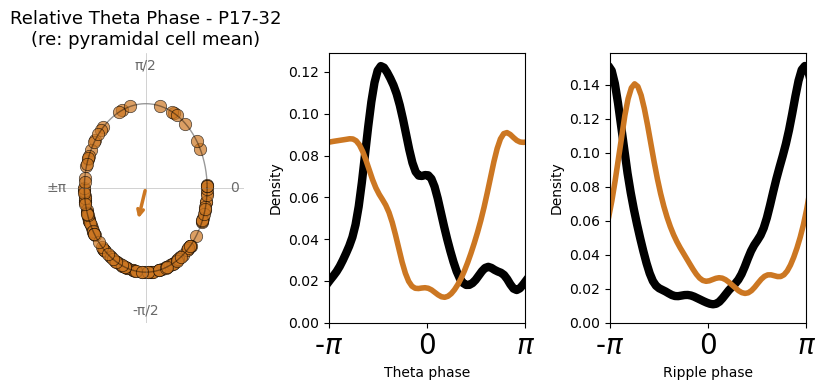

C:\Users\Florencia\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Florencia\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Florencia\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Florencia\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be

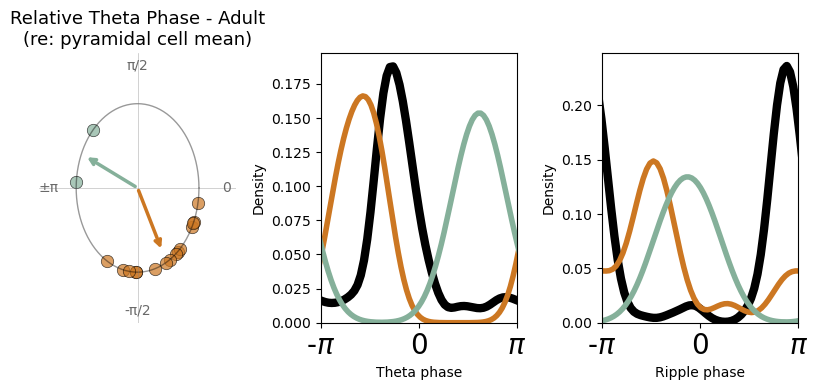

In [16]:
xticks = [-np.pi, 0, np.pi, 2*np.pi, 3*np.pi, 4*np.pi, 5*np.pi]
xtick_labels = [r'$-\pi$', '0', r'-$\pi$', '0', r'$\pi$', r'$4\pi$', r'$5\pi$']

for i, group in enumerate(age_labels):
    ripp_mod = np.array(inhib_neurons[group]['ripp_mod'])
    ripp_mod_sign = np.array(inhib_neurons[group]['ripp_mod_sign'])
    theta_inhib = np.array(inhib_neurons[group]['theta_phase'])
    theta_inhib_sign = np.array(inhib_neurons[group]['theta_lock_sign'])
    theta_exc = np.array(exc_neurons[group]['theta_phase'])
    theta_exc_sign = np.array(exc_neurons[group]['theta_lock_sign'])
    ripp_phase_exc = np.array(exc_neurons[group]['ripp_phase'])
    ripp_phase_inhib = np.array(inhib_neurons[group]['ripp_phase'])
    
    exc_mask = (theta_exc_sign == 1)
    valid_exc_theta = theta_exc[exc_mask]
    mean_exc_phase = circmean(valid_exc_theta, low=-np.pi, high=np.pi)

  #  AA_OLM_mask = (np.abs(ripp_mod) < 1000) & (ripp_mod < 0)
    AA_OLM_mask = (np.abs(ripp_mod) < 1000) & (ripp_mod > 0)
    theta_AA_OLM = theta_inhib[AA_OLM_mask]

    if len(theta_AA_OLM) == 0:
        continue

    # Relative phase
    theta_AA_OLM_rel = wrap_to_pi(theta_AA_OLM - mean_exc_phase)

    # Clustering
    phase_AA_OLM_x = np.cos(theta_AA_OLM_rel)
    phase_AA_OLM_y = np.sin(theta_AA_OLM_rel)
    data_AA_OLM = np.column_stack([phase_AA_OLM_x, phase_AA_OLM_y])

    # Run DBSCAN
    dbscan = DBSCAN(eps=0.8, min_samples=2) 
    subset_labels = dbscan.fit_predict(data_AA_OLM)

    # Run GGM
 #   gmm = GaussianMixture(n_components=2, random_state=42)
 #   subset_labels = gmm.fit_predict(data_AA_OLM)

    # Store full-length labels (NaN for neurons outside mask)
    n_neurons = len(theta_inhib)
    full_cluster_labels = np.full(n_neurons, np.nan)
    full_cluster_labels[AA_OLM_mask] = subset_labels
    inhib_neurons[group]['cluster_labels'] = full_cluster_labels

    # ---- Plot ----
    fig, (ax1,ax2, ax3) = plt.subplots(1, 3, figsize=(8, 4))

    # Unit circle
    theta_circle = np.linspace(0, 2 * np.pi, 300)
    ax1.plot(np.cos(theta_circle), np.sin(theta_circle), 'k-', linewidth=1, alpha=0.4)
    ax1.axhline(y=0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)
    ax1.axvline(x=0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)

    for label in np.unique(subset_labels):
        # ---- Use subset_labels to index theta_AA_OLM_rel (both are subset-length) ----
        mask = (subset_labels == label)
        phases = theta_AA_OLM_rel[mask]

        if len(phases) == 0:
            continue

        color = label_colors.get(label, 'gray')

        # Scatter on unit circle
        ax1.scatter(np.cos(phases), np.sin(phases),
                    c=color, label=f'Cluster {label} (n={mask.sum()})',
                    s=80, marker='o', alpha=0.7,
                    edgecolors='black', linewidths=0.5)

        # Mean resultant vector arrow
        mean_rel = circmean(phases, low=-np.pi, high=np.pi)
        R = np.abs(np.mean(np.exp(1j * phases)))
        ax1.annotate('', 
                     xy=(R * np.cos(mean_rel), R * np.sin(mean_rel)),
                     xytext=(0, 0),
                     arrowprops=dict(arrowstyle='->', color=color, lw=2.5))

    # Phase labels around circle
    phase_ticks = {0: '0', np.pi/2: 'π/2', np.pi: '±π', -np.pi/2: '-π/2'}
    for angle, label_text in phase_ticks.items():
        x = 1.45 * np.cos(angle)
        y = 1.45 * np.sin(angle)
        ax1.text(x, y, label_text, ha='center', va='center', fontsize=10, color='dimgray')

    ax1.set_xlim(-1.6, 1.6)
    ax1.set_ylim(-1.6, 1.6)
    ax1.axis('off')
    ax1.set_title(f'Relative Theta Phase - {group}\n(re: pyramidal cell mean)', fontsize=13)

    # --- KDE --- #
    mask_group1 = (inhib_neurons[group]['cluster_labels'] == 0)
    mask_group2 = (inhib_neurons[group]['cluster_labels'] == 1)

    exc_theta_subset = np.concatenate([valid_exc_theta, valid_exc_theta + 2*np.pi, valid_exc_theta + 4*np.pi])
    inhib_theta_subset1 = np.concatenate([theta_inhib[mask_group1], theta_inhib[mask_group1] + 2*np.pi, theta_inhib[mask_group1] + 4*np.pi])
    inhib_theta_subset2 = np.concatenate([theta_inhib[mask_group2], theta_inhib[mask_group2] + 2*np.pi, theta_inhib[mask_group2] + 4*np.pi])
    
    sns.kdeplot(exc_theta_subset, ax=ax2, bw_adjust=0.2, color='k', linewidth=6)
    sns.kdeplot(inhib_theta_subset1, ax=ax2, bw_adjust=0.2, color=label_colors.get(0, 'gray'), linewidth=4)
    sns.kdeplot(inhib_theta_subset2, ax=ax2, bw_adjust=0.2, color=label_colors.get(1, 'gray'), linewidth=4)

    ax2.set_xticks(xticks)
    ax2.set_xticklabels(xtick_labels, fontsize=20)
    ax2.set_xlim(np.pi, 3*np.pi)
    ax2.set_xlabel('Theta phase')

    exc_ripp_subset = np.concatenate([ripp_phase_exc, ripp_phase_exc + 2*np.pi, ripp_phase_exc + 4*np.pi])
    inhib_ripp_subset1 = np.concatenate([ripp_phase_inhib[mask_group1], ripp_phase_inhib[mask_group1] + 2*np.pi, ripp_phase_inhib[mask_group1] + 4*np.pi])
    inhib_ripp_subset2 = np.concatenate([ripp_phase_inhib[mask_group2], ripp_phase_inhib[mask_group2] + 2*np.pi, ripp_phase_inhib[mask_group2] + 4*np.pi])
    
    sns.kdeplot(exc_ripp_subset, ax=ax3, bw_adjust=0.2, color='k', linewidth=6)
    sns.kdeplot(inhib_ripp_subset1, ax=ax3, bw_adjust=0.2, color=label_colors.get(0, 'gray'), linewidth=4)
    sns.kdeplot(inhib_ripp_subset2, ax=ax3, bw_adjust=0.2, color=label_colors.get(1, 'gray'), linewidth=4)

    ax3.set_xticks(xticks)
    ax3.set_xticklabels(xtick_labels, fontsize=20)
    ax3.set_xlim(np.pi, 3*np.pi)
    ax3.set_xlabel('Ripple phase')
    
    plt.tight_layout()
    plt.show()



In [ ]:
label_colors = {-1: 'white', 0: '#CC7722', 1: '#85B09A', 2: '#505086', 3: '#A31621', 4: '#7A86C0', 
                5: '#E3B23C', 6: '#A3BCF9', 7: '#C3642F', 8: '#54615E'}

for i, group in enumerate( age_labels):
    
    mask_group1 = (inhib_neurons[group]['cluster_labels']==0)
    mask_group2 = (inhib_neurons[group]['cluster_labels']==1)
    
    # ---- Plot identified clusters ---- #
    fig, (ax1, ax2) = plt.subplots(1,2, figsize=(6, 6))

    # Draw unit circle
    theta_circle = np.linspace(0, 2 * np.pi, 300)
    ax1.plot(np.cos(theta_circle), np.sin(theta_circle), 'k-', linewidth=1, alpha=0.4)

    # Draw axes lines through origin
    ax1.axhline(y=0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)
    ax1.axvline(x=0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)

    for label in unique_labels:
        mask = (cluster_labels == label)
        
        color = label_colors.get(label, 'gray')
        label_name = f'Cluster {label}'

        # Convert relative phases to cartesian coordinates on the unit circle
        phases = theta_AA_OLM_rel[mask]
        x = np.cos(phases)
        y = np.sin(phases)

        ax1.scatter(x, y,
               c=color, label=label_name,
               s=80, marker='o', alpha=0.7,
               edgecolors='black', linewidths=0.5)

    # Plot mean excitatory phase reference as an arrow at phase=0 (by definition)
    ax1.annotate('', xy=(1.15, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='blue', lw=2))
    ax1.text(1.2, 0.05, 'Exc\nmean', color='blue', fontsize=9, ha='center')

    # Plot mean relative phase per cluster as arrows from origin
    for label in sorted(unique_labels):
        if label == -1:
            continue
        mask = (cluster_labels == label)
        phases = theta_AA_OLM_rel[mask]
        mean_rel = circmean(phases, low=-np.pi, high=np.pi)
        R = np.abs(np.mean(np.exp(1j * phases)))  # resultant length = arrow length
        color = label_colors.get(label, 'gray')

        ax1.annotate('', 
                xy=(R * np.cos(mean_rel), R * np.sin(mean_rel)), 
                xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=color, lw=2.5))

    # Add phase labels around the circle
    phase_ticks = {0: '0', np.pi/2: 'π/2', np.pi: '±π', -np.pi/2: '-π/2'}
    for angle, label_text in phase_ticks.items():
        x = 1.25 * np.cos(angle)
        y = 1.25 * np.sin(angle)
        ax1.text(x, y, label_text, ha='center', va='center', fontsize=10, color='dimgray')

    ax1.set_xlim(-1.6, 1.6)
    ax1.set_ylim(-1.6, 1.6)
    ax1.axis('off')
    ax1.set_title(f'Relative Theta Phase - {group}\n(re: pyramidal cell mean)', fontsize=13)

    
    plt.tight_layout()
    plt.show()



In [ ]:
from matplotlib.gridspec import GridSpec
import seaborn as sns

fig = plt.figure(figsize=(2.5, 8))
gs = GridSpec(nrows=len(age_labels), ncols=1, hspace=0.3)

axes = []

for i in range(len(age_labels)):
    ax = fig.add_subplot(gs[i])
    axes.append(ax)

for i, (ax, group) in enumerate(zip(axes, age_labels)):
    
    # Get all arrays
    phases = np.array(inhib_neurons[group]['theta_phase'])
    theta_signs = np.array(inhib_neurons[group]['theta_lock_sign'])
    mods = np.array(inhib_neurons[group]['ripp_mod'])
    ripp_signs = np.array(inhib_neurons[group]['ripp_mod_sign'])
    
    # Create a single mask for neurons that meet ALL criteria
  #  valid_mask = (theta_signs == 1) & (ripp_signs == 1) & (np.abs(mods) < 1000)
    valid_mask = (np.abs(mods) < 1000)
    
    # Apply mask to get matching phase and modulation values
    phase_inhib = phases[valid_mask]
    mod_inhib = mods[valid_mask]

    print(np.size(phase_inhib), np.size(mod_inhib))
    
    # --- Scatter plot ---
    ax.scatter(phase_inhib, mod_inhib,
               color=palette[i], s=40, alpha=0.7, label='Inhib')
    
    # --- Formatting ---
    ax.set_xlim(-np.pi, np.pi)
    ax.set_xticks([-np.pi, 0, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'0', r'$\pi$'], fontsize=20)

    ax.set_ylim(-10, 18)
    ax.set_yticks([-8, 0, 8, 16])
    
    ax.set_ylabel('Ripp. mod.', fontsize=22)
    ax.tick_params(axis='both', labelsize=18)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# X label only on last subplot
axes[-1].set_xlabel('Theta phase', fontsize=24)

#plt.savefig('ripple_phase_vs_mod_scatter.pdf', format='pdf', bbox_inches='tight')
plt.tight_layout()

Find clustering of interneurons based on spiking patterns during theta

In [ ]:
from kneed import KneeLocator
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

In [ ]:
for i, age in enumerate(age_labels):
    
#    phase_inhib = np.array([phase for phase,sign in zip(inhib_neurons[age]['theta_phase'], inhib_neurons[age]['theta_lock_sign']) if sign==1])
#    mod_inhib = np.array([mod for mod,sign in zip(inhib_neurons[age]['ripp_mod'], inhib_neurons[age]['ripp_mod_sign']) if sign==1 and np.abs(mod)<1000])

    # Convert circular phase to cartesian coordinates
    phase_x = np.cos(phase_inhib)
    phase_y = np.sin(phase_inhib)

    # Scale modulation scores to have mean=0 and std=1. this avoids giving mod too much weight when clustering, when compared with theta phase
    scaler = StandardScaler()
    mod_scaled = scaler.fit_transform(mod_inhib.reshape(-1,1)).flatten()

    # Combine features for clustering
    data = np.column_stack([phase_x, phase_y, mod_scaled])

    # Clustering
    # Find optimal epsilon value
    min_neighbors = 2
    neigh = NearestNeighbors(n_neighbors=min_neighbors)
    neigh.fit(data)
    distances, _ = neigh.kneighbors(data)
    distances = np.sort(distances[:, min_neighbors-1])

    # Identify index of elbow
    x = range(len(distances))
    kneedle = KneeLocator(x, distances, S=0.5, curve='convex', direction='increasing', interp_method='interp1d')
    elbow_index = kneedle.elbow
    epsilon = distances[elbow_index]

    # Optional
    plt.figure(figsize=(10, 6))
    plt.plot(distances)
    plt.scatter(elbow_index, epsilon, color='red', label=f'Elbow (ε={epsilon:.2f})')
    plt.xlabel('Points')
    plt.ylabel(f'{min_neighbors}-th nearest neighbor distance')
    plt.title('K-distance Graph')
    plt.show()

    # Run DBSCAN
    dbscan = DBSCAN(eps=epsilon, min_samples=min_neighbors) 
    inhib_neurons[age]['cluster_labels'] = dbscan.fit_predict(data)

    # Plot identified clusters
    label_colors = {-1: 'white', 0: '#CC7722', 1: '#85B09A', 2: '#505086', 3: '#A31621', 4: '#7A86C0', 
                    5: '#E3B23C', 6: '#A3BCF9', 7: '#C3642F', 8: '#54615E'}
    
    fig, ax = plt.subplots(figsize=(8, 3))
    
    cluster_labels = inhib_neurons[age]['cluster_labels']
    unique_labels = set(cluster_labels)
    
    for label in unique_labels:
        mask = cluster_labels == label
        color = label_colors.get(label, 'gray')
        
        marker = 'o'
        edgecolor = 'black'
        label_name = f'Cluster {label}'
        
        # Plot phase on x-axis, y=0 for all points (on a line)
        ax.scatter(phase_inhib[mask], np.zeros(np.sum(mask)), 
                   c=color, label=label_name, 
                   s=80, marker=marker, alpha=0.7,
                   edgecolors=edgecolor, linewidths=0.5)
    
    # Formatting
    ax.set_xlim(-np.pi - 0.2, np.pi + 0.2)
    ax.set_ylim(-0.5, 0.5)
    ax.set_xlabel('Theta Phase (radians)', fontsize=12)
    ax.set_yticks([])  # Remove y-axis ticks since all points are at y=0
    
    # Add x-axis labels at key phase values
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels(['-π', '-π/2', '0', 'π/2', 'π'])
    
    ax.set_title(f'Theta Phase Clusters - {age}', fontsize=14)
#    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3, axis='x')
    ax.axhline(y=0, color='gray', linestyle='-', linewidth=0.5)
    
    plt.tight_layout()
    plt.show()
    
    print(f"{age}: Found {len(unique_labels) - (1 if -1 in unique_labels else 0)} clusters, "
          f"{np.sum(cluster_labels == -1)} noise points")
    

    print(age, inhib_neurons[age]['cluster_labels'])


In [ ]:
from sklearn.neighbors import NearestNeighbors
from kneed import KneeLocator
from sklearn.cluster import DBSCAN

In [ ]:
from sklearn.preprocessing import StandardScaler

reduced_data = inhib_fr["Adult"]['fr']

min_neighbors = 2

neigh = NearestNeighbors(n_neighbors=min_neighbors)
neigh.fit(reduced_data)
distances, _ = neigh.kneighbors(reduced_data)
distances = np.sort(distances[:, min_neighbors-1])

# Identify index of elbow
x = range(len(distances))
kneedle = KneeLocator(x, distances, S=0.5, curve='convex', direction='increasing', interp_method='interp1d')
elbow_index = kneedle.elbow
epsilon = distances[elbow_index]

plt.figure(figsize=(10, 6))
plt.plot(distances)
plt.scatter(elbow_index, epsilon, color='red', label=f'Elbow (ε={epsilon:.2f})')
plt.xlabel('Points')
plt.ylabel(f'{min_neighbors}-th nearest neighbor distance')
plt.title('K-distance Graph')
plt.show()



In [ ]:
# Identify clusters
print(epsilon)
dbscan = DBSCAN(eps=epsilon, min_samples= min_neighbors)
inhib_fr['Adult']['cluster_labels'] = dbscan.fit_predict(reduced_data)

print(np.array(inhib_fr['Adult']['cluster_labels']))


In [ ]:
number_interneurons = len(inhib_fr['Adult']['cluster_labels'])

for i in range(number_interneurons-1):
    fig, ax_fr = plt.subplots()
    ax_fr.plot(reduced_data[i], color='b')
    ax_fr.axvline(x=bins_notRipp, linestyle='--', color='gray', label='Ripple Start')
    ax_fr.axvline(x=(bins_notRipp+bins_ripp), linestyle='--', color='gray', label='Ripple End')
    ax_fr.set_ylabel('Firing Rate (Hz)')
    ax_fr.set_xlabel('Time (normalized)')
    ax_fr.set_title(f"Cluster: {inhib_fr['Adult']['cluster_labels'][i]}")

In [ ]:
from matplotlib.gridspec import GridSpec
import seaborn as sns

fig = plt.figure(figsize=(4.5, 10))
# Create GridSpec with 1 + len(age_groups) rows, top subplot half height, others equal height
gs = GridSpec(nrows=len(age_labels), ncols=1, hspace=0.2)
axes_left = []
axes_right = []

for i in range(len(age_labels)):
    ax_left = fig.add_subplot(gs[i])
    ax_right = ax_left.twinx()  # Create twin axis sharing x-axis
    axes_left.append(ax_left)
    axes_right.append(ax_right)
    
for i, (ax_left, ax_right, group) in enumerate(zip(axes_left, axes_right, age_labels)):
    mod_inhib = np.array(inhib_fr[group]['mod'])
    print(mod_inhib)
#    mod_exc = np.array(exc_fr[group]['mod'])
    
    # Plot exc on left axis
#    sns.kdeplot(data=mod_exc, ax=ax_left, bw_adjust=0.5, color=palette[i], linewidth=4)
    # Plot inhib on right axis
    sns.kdeplot(data=mod_inhib, ax=ax_right, bw_adjust=0.5, color=palette[i], linewidth=2, linestyle='--')
       
    # Set x-axis limits to show 2 cycles
#    ax_left.set_xlim(-0.02, 0.05)
    
    # Left axis formatting
    ax_left.tick_params(axis='both', labelsize=20)
    ax_left.set_xlabel('')
    ax_left.set_ylabel('PDE \n (Exc.)', fontsize=24, color='k')
    ax_left.tick_params(axis='y', labelcolor='k')
    ax_left.spines['top'].set_visible(False)
    ax_left.spines['bottom'].set_visible(False)
    ax_left.spines['left'].set_color('k')
    
    # Right axis formatting
    ax_right.set_ylabel('PDE \n (Inhib.)', fontsize=24, color='k')
    ax_right.tick_params(axis='y', labelsize=20, labelcolor='k')
    ax_right.spines['top'].set_visible(False)
    ax_right.spines['bottom'].set_visible(False)
    ax_right.spines['right'].set_color('k')
    
    if i != len(age_labels) - 1:
        # Hide x-ticks for all but last
        ax_left.set_xticks([])
        ax_left.set_xticklabels([])
        
# Show xticks and spine only for the last subplot
axes_left[-1].spines['bottom'].set_visible(True)
axes_left[-1].set_xlabel('Ripple modulation', fontsize=24)
#plt.suptitle('Probability Density Function', fontsize=24)
plt.savefig('ripp_mod1.pdf', format='pdf', bbox_inches='tight')
plt.tight_layout()

In [ ]:
# Theta phase

inhib_info = defaultdict(lambda:defaultdict(list))

for trial in trial_files:
    file_path = os.path.join(pathway_win,trial)

    with h5py.File(file_path,'r') as f:
        cell_type = f['cell_type'][:]
        theta_phase = f['theta_phase'][:]
        theta_lock_sign = f['theta_lock_sign'][:]

    match = re.search(r"P(\d+)", trial)
    age = int(match.group(1))
    age_entry = age_group(age)

    inhib_mask = (cell_type==b'inhib')

    # Spiking patterns of inhib neurons
    theta_phase_inhib = theta_phase[inhib_mask]
    theta_lock_sign_inhib = theta_lock_sign[inhib_mask]

    inhib_info[age_entry]['theta_phase'].extend(theta_phase_inhib)
    inhib_info[age_entry]['theta_lock_sign'].extend(theta_lock_sign_inhib)

In [ ]:
# Plots
xticks = [-np.pi, 0, np.pi, 2*np.pi, 3*np.pi, 4*np.pi, 5*np.pi]
xtick_labels = [r'$-\pi$', '0', r'-$\pi$', '0', r'$\pi$', r'$4\pi$', r'$5\pi$']
fig = plt.figure(figsize=(4, 11))
# Create GridSpec with 1 + len(age_groups) rows, top subplot half height, others equal height
gs = GridSpec(nrows=1 + len(age_labels), ncols=1, height_ratios=[0.5] + [1]*len(age_labels), hspace=0.3)
# Top subplot for periodic line plot
ax_top = fig.add_subplot(gs[0])
# Generate periodic signal for 3 cycles (-pi to 5*pi)
x = np.linspace(-np.pi, 5*np.pi, 600)
y = np.cos(x)  # example periodic signal, change to any periodic function you want
ax_top.plot(x, y, color='black', lw=2)
ax_top.set_xlim(np.pi, 3*np.pi)
ax_top.set_xticklabels([]) 
ax_top.set_yticklabels([]) 
ax_top.set_yticks([]) 
ax_top.set_xticks([]) 
ax_top.spines['top'].set_visible(False)
ax_top.spines['right'].set_visible(False)
ax_top.spines['bottom'].set_visible(False)
ax_top.spines['left'].set_visible(False)
# Bottom subplots for histograms
axes = []
for i in range(len(age_labels)):
    ax = fig.add_subplot(gs[i+1])
    axes.append(ax)
    
for i, (ax, group) in enumerate(zip(axes, age_labels)):
    inhib_subset = np.array([phase for phase,sign in zip(inhib_info[group]['theta_phase'], inhib_info[group]['theta_lock_sign']) if sign==1])
    inhib_subset = np.concatenate([inhib_subset, inhib_subset+2*np.pi, inhib_subset+4*np.pi])
    
    sns.kdeplot(inhib_subset, ax=ax, bw_adjust=0.2, color=palette[i], linewidth=2, linestyle='--')
    
    # Set x-axis limits to show 3 cycles
    ax.set_xticks(xticks)
    ax.set_xticklabels(xtick_labels, fontsize=20)
    ax.set_xlim(np.pi, 3*np.pi)
    ax.set_ylim(0, 0.25)
    
    ax.tick_params(axis='both', labelsize=20)
    ax.set_xlabel('')
    ax.set_ylabel('PDE', fontsize=24)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
#    ax.spines['bottom'].set_visible(False)
#    if i != len(age_labels) - 1:
#        # Hide x-ticks for all but last
#        ax.set_xticks(xticks)
#        ax.set_xticklabels(xtick_labels, fontsize=20)
#        ax.set_xticks([])
#        ax.set_xticklabels([])
        
# Show xticks and spine only for the last subplot
axes[-1].spines['bottom'].set_visible(True)
axes[-1].set_xticks(xticks)
axes[-1].set_xticklabels(xtick_labels, fontsize=20)
axes[-1].set_xlim(np.pi, 3*np.pi)
axes[-1].set_ylim(0, 0.25)
axes[-1].set_xlabel('Theta phase', fontsize=24)
plt.savefig('theta_dist.pdf', format='pdf', bbox_inches='tight')
plt.tight_layout()